# Bank Customer Churn Prediction – Decision Tree

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


#1. Loading data

In [44]:
df = pd.read_csv('bank.csv', na_values=['-', ' ', ''])

display(df.head())
df.info()


,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction.Score,Card.Type,Point.Earned
0,Hargrave,619,France,Female,NaN,2,0.00,1,1,1,101348.88,1,2,DIAMOND,464
1,Hill,608,Spain,Female,41.0,1,83807.86,1,0,1,112542.58,0,3,DIAMOND,456
2,Onio,502,France,Female,42.0,8,159660.80,3,1,0,113931.57,1,3,DIAMOND,377
3,Boni,699,France,Female,39.0,1,0.00,2,0,0,93826.63,0,5,GOLD,350
4,NaN,850,Spain,Female,43.0,2,125510.82,1,1,1,79084.10,0,5,GOLD,425


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Surname             4897 non-null   object 
 1   CreditScore         4898 non-null   int64  
 2   Geography           4896 non-null   object 
 3   Gender              4898 non-null   object 
 4   Age                 4895 non-null   float64
 5   Tenure              4898 non-null   int64  
 6   Balance             4898 non-null   float64
 7   NumOfProducts       4898 non-null   int64  
 8   HasCrCard           4898 non-null   int64  
 9   IsActiveMember      4898 non-null   int64  
 10  EstimatedSalary     4898 non-null   float64
 11  Exited              4898 non-null   int64  
 12  Satisfaction.Score  4898 non-null   int64  
 13  Card.Type           4898 non-null   object 
 14  Point.Earned        4898 non-null   int64  
dtypes: float64(3), int64(8), object(4)
memory usage: 574.1+

#2. Creating a subset with a new target column

In [45]:
# Creating the Stayed variable from Exited
# Checking for missing values in Exited

print("Exited contains missing values:", df['Exited'].isna().any())
df['Stayed'] = np.where(df['Exited'] == 0, 'Yes', 'No')   # the positive class is Yes

# Encoding the target as 1 and 0 for numerical classification
df['Stayed'] = df['Stayed'].map({'Yes': 1, 'No': 0})

# Removing the column Exited because it was used to derive the target (preventing target leakage)
df.drop(columns='Exited', inplace=True)


Exited contains missing values: False


In [46]:
# Filling the missing values with the median value of that column
print(df['Age'].isna().sum())
df['Age'] = df['Age'].fillna(df['Age'].median())

df = df[df['Age'] <= 87]
print(df['Age'].describe())

3
count    4897.000000
mean       38.966919
std        10.588510
min        18.000000
25%        32.000000
50%        37.000000
75%        44.000000
max        85.000000
Name: Age, dtype: float64


### Handling Missing Values

In [47]:
print("Missing values:\n", df.isna().sum())
# Columns Surname and Geography contain missing values
# Surname will be removed later because it is not relevant for predicting the target

Missing values:
 Surname               1
CreditScore           0
Geography             2
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction.Score    0
Card.Type             0
Point.Earned          0
Stayed                0
dtype: int64


In [48]:
#Replacing missing Geography values with the most frequent category
df['Geography'] = df['Geography'].fillna(df['Geography'].mode()[0])
df.Geography.isnull().sum()

np.int64(0)

### Feature Selection and Relevance Assessment

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4897 entries, 0 to 4897
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Surname             4896 non-null   object 
 1   CreditScore         4897 non-null   int64  
 2   Geography           4897 non-null   object 
 3   Gender              4897 non-null   object 
 4   Age                 4897 non-null   float64
 5   Tenure              4897 non-null   int64  
 6   Balance             4897 non-null   float64
 7   NumOfProducts       4897 non-null   int64  
 8   HasCrCard           4897 non-null   int64  
 9   IsActiveMember      4897 non-null   int64  
 10  EstimatedSalary     4897 non-null   float64
 11  Satisfaction.Score  4897 non-null   int64  
 12  Card.Type           4897 non-null   object 
 13  Point.Earned        4897 non-null   int64  
 14  Stayed              4897 non-null   int64  
dtypes: float64(3), int64(8), object(4)
memory usage: 612.1+ KB


In [50]:
#Removing column Surname because it is not a meaningful predictor of customer churn
df = df.drop(columns=['Surname'])

#3. Evaluating distribution of the columns

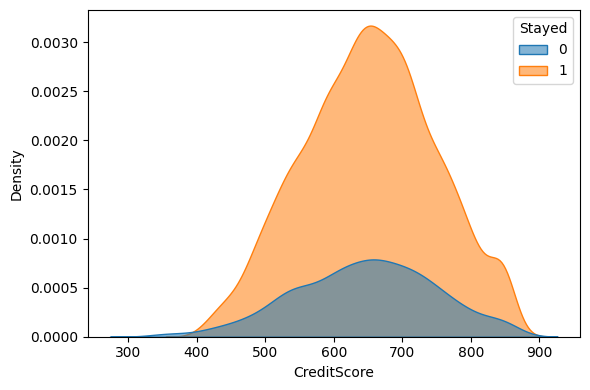

In [51]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='CreditScore', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

#Excluding the column CreditScore because the distributions for Stayed (Yes/No) almost completely overlap, suggesting limited class separation.
df.drop(columns=['CreditScore'], inplace=True)

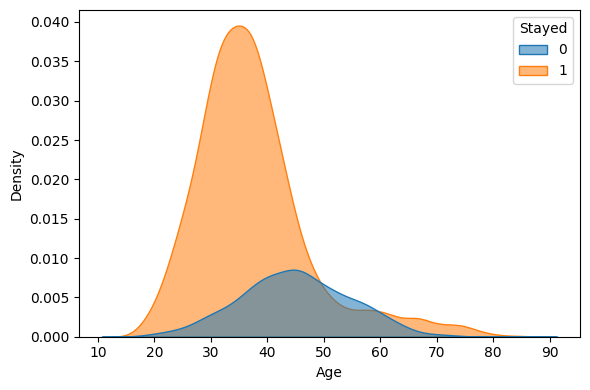

In [52]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='Age', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

# For column Age, distribution differ between target classes, so it will be included in the model.

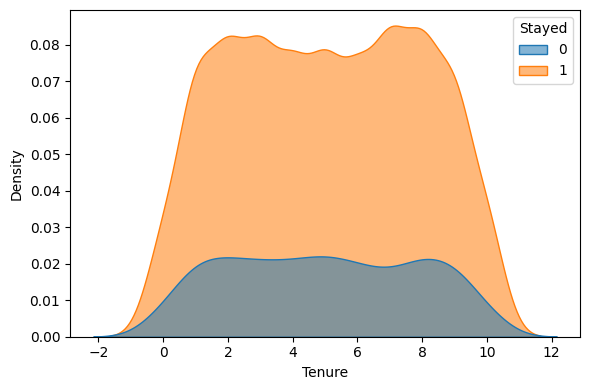

In [53]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='Tenure', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

#Excluding column Tenure because the distributions for Stayed (Yes/No) largely overlap, suggesting limited class separation.
df.drop(columns=['Tenure'], inplace=True)

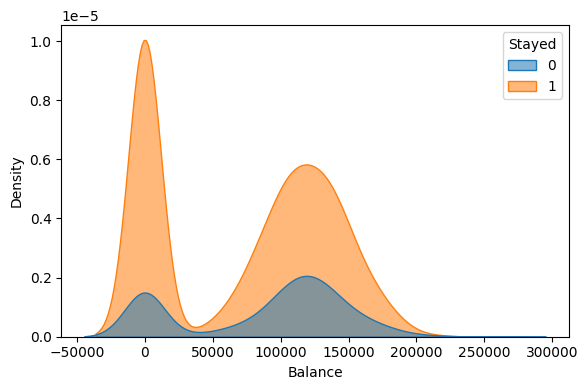

In [54]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='Balance', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

# For column Balance, distribution differ between target classes, so it will be included in the model.

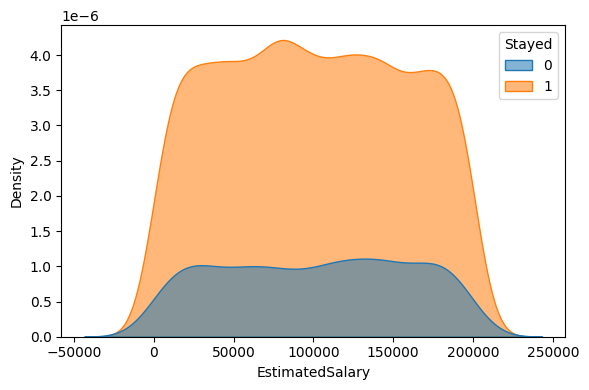

In [55]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='EstimatedSalary', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

# Excluding column EstimatedSalary because the density curves for both classes largely overlap, suggesting limited class separation.
df.drop(columns=['EstimatedSalary'], inplace=True)

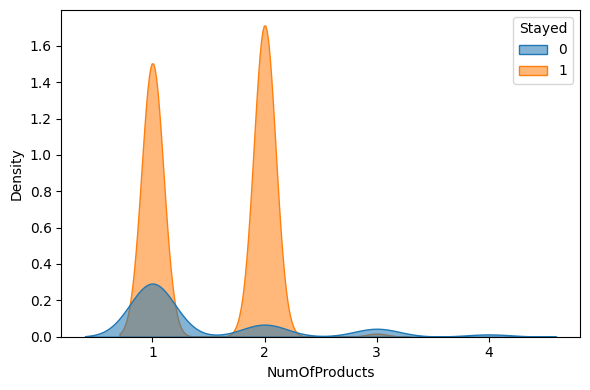

In [56]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='NumOfProducts', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

# Column NumOfProducts may help distinguish customers who stay from those who leave.

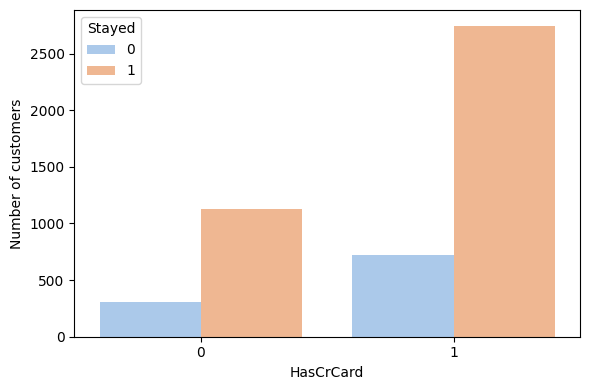

In [57]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='HasCrCard', hue='Stayed', palette='pastel')
plt.xlabel('HasCrCard')
plt.ylabel('Number of customers')
plt.legend(title='Stayed')
plt.tight_layout()
plt.show()

#Excluding column HasCrCard because the proportions of customers with and without credit cards are similar across the two classes.
df.drop(columns=['HasCrCard'], inplace=True)

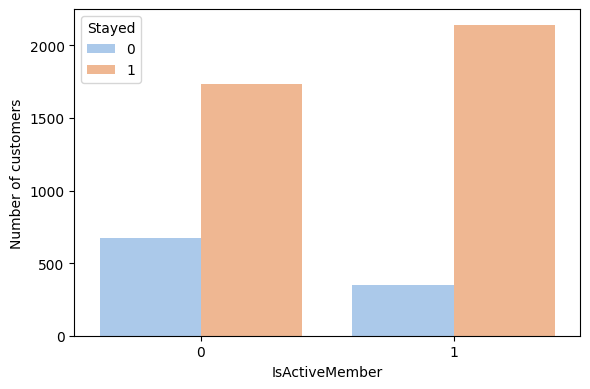

In [58]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='IsActiveMember', hue='Stayed', palette='pastel')
plt.xlabel('IsActiveMember')
plt.ylabel('Number of customers')
plt.legend(title='Stayed')
plt.tight_layout()
plt.show()

# The class proportions differ for IsActiveMember=0 and IsActiveMember=1, so IsActiveMember will be included in the model.

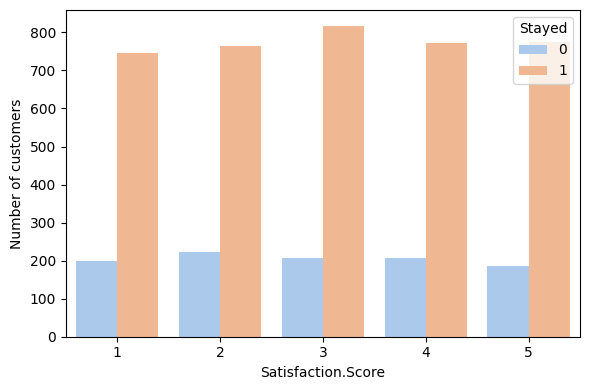

In [59]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Satisfaction.Score', hue='Stayed', palette='pastel')
plt.xlabel('Satisfaction.Score')
plt.ylabel('Number of customers')
plt.legend(title='Stayed')
plt.tight_layout()
plt.show()

#The bar chart shows similar class proportions across Satisfaction.Score levels, so this feature will be excluded.
df.drop(columns=['Satisfaction.Score'], inplace=True)

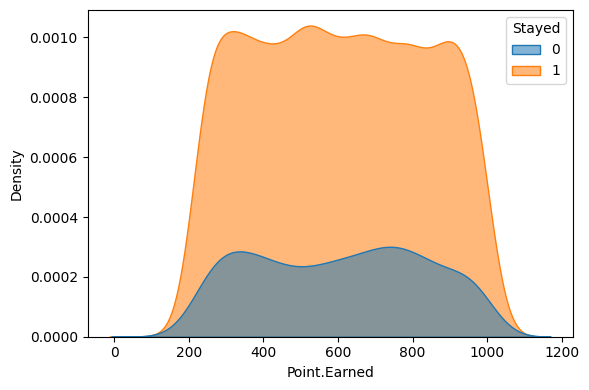

In [60]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='Point.Earned', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

# Excluding column Point.Earned because the density curves for both classes largely overlap, suggesting limited class separation.
df.drop(columns=['Point.Earned'], inplace=True)

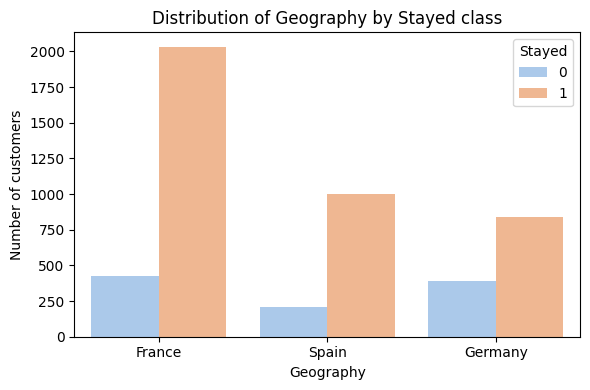

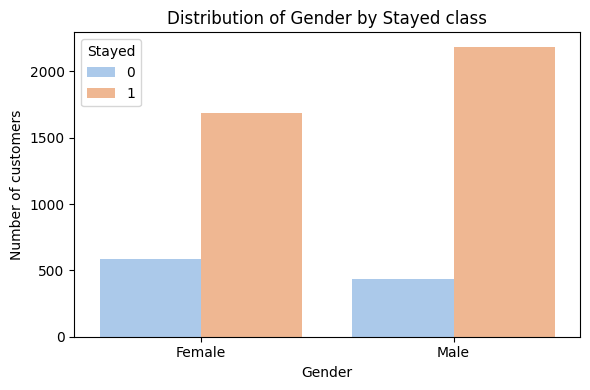

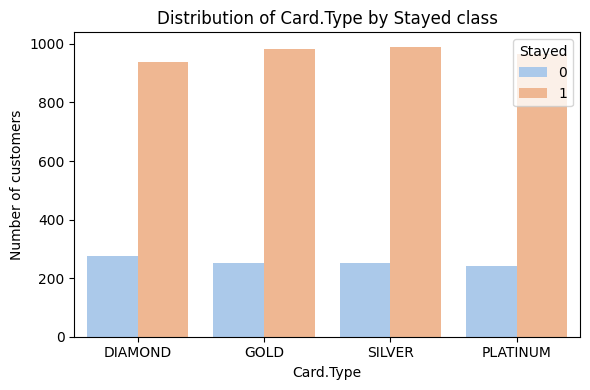

In [61]:
# Bar charts for Geography, Gender and Card.Type grouped by Stayed
for col in ['Geography', 'Gender', 'Card.Type']:
    plt.figure(figsize=(6,4))
    sns.countplot(data=df, x=col, hue='Stayed', palette='pastel')
    plt.title(f'Distribution of {col} by Stayed class')
    plt.xlabel(col)
    plt.ylabel('Number of customers')
    plt.legend(title='Stayed')
    plt.tight_layout()
    plt.show()

In [62]:
#Retain Geography because the Stayed proportions differ across countries (e.g., a larger share of customers from France stay than those from Spain and Germany).
#IsActiveMember shows a clear difference in class proportions and should be retained, whereas HasCrCard offers limited separation.
df.drop(columns=['Card.Type'], inplace=True)

#4. Encoding Categorical Variables

In [63]:
df.select_dtypes(include=object).info()

<class 'pandas.core.frame.DataFrame'>
Index: 4897 entries, 0 to 4897
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Geography  4897 non-null   object
 1   Gender     4897 non-null   object
dtypes: object(2)
memory usage: 114.8+ KB


In [64]:
#Evaluating remaining string variables by their type (ordinal or categorical), number of distinct values and distribution
df_vars = df.select_dtypes(include=object).columns.tolist()
for df_var in df_vars:
    print(f"{df_var}: {df[df_var].nunique()}")
#Both variables have a small number of distinct values

Geography: 3
Gender: 2


In [65]:
df.Geography.value_counts()

,count
Geography,
France,2456
Germany,1231
Spain,1210


In [66]:
df.Gender.value_counts()

,count
Gender,
Male,2623
Female,2274


In [67]:
from sklearn.preprocessing import OneHotEncoder

#Using One-Hot Encoding because Geography and Gender are categorical
ohe = OneHotEncoder(sparse_output=False)
cats = ['Geography', 'Gender']
encoded_array = ohe.fit_transform(df[cats])
encoded_cols = ohe.get_feature_names_out(cats)

df_ohe = pd.DataFrame(encoded_array, columns=encoded_cols, index=df.index)
df = df.drop(columns=cats).join(df_ohe)

In [68]:
df.head(10)

,Age,Balance,NumOfProducts,IsActiveMember,Stayed,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,37.0,0.00,1,1,0,1.0,0.0,0.0,1.0,0.0
1,41.0,83807.86,1,1,1,0.0,0.0,1.0,1.0,0.0
2,42.0,159660.80,3,0,0,1.0,0.0,0.0,1.0,0.0
3,39.0,0.00,2,0,1,1.0,0.0,0.0,1.0,0.0
4,43.0,125510.82,1,1,1,0.0,0.0,1.0,1.0,0.0
5,44.0,113755.78,2,0,0,0.0,0.0,1.0,0.0,1.0
6,50.0,0.00,2,1,1,1.0,0.0,0.0,0.0,1.0
7,29.0,115046.74,4,0,0,0.0,1.0,0.0,1.0,0.0
8,44.0,142051.07,2,1,1,1.0,0.0,0.0,0.0,1.0
9,27.0,134603.88,1,1,1,1.0,0.0,0.0,0.0,1.0


#5. Train/Test Split

In [69]:
X = df.drop(columns='Stayed')
y = df['Stayed']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Class distribution in training and test sets
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Stayed
1    0.791167
0    0.208833
Name: proportion, dtype: float64
Stayed
1    0.790816
0    0.209184
Name: proportion, dtype: float64


#6. Finding the Optimal `ccp_alpha`

In [70]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV,StratifiedKFold

cv  = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
param_grid = {'ccp_alpha':np.arange(0.0,0.05,0.0025)}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                    param_grid=param_grid,
                    cv=cv,
                    scoring='accuracy')
grid.fit(X_train, y_train)

best_ccp_alpha = grid.best_params_['ccp_alpha']
print("Best ccp_alpha value:",best_ccp_alpha)

Best ccp_alpha value: 0.005


#7. Training and Visualizing the Decision Tree

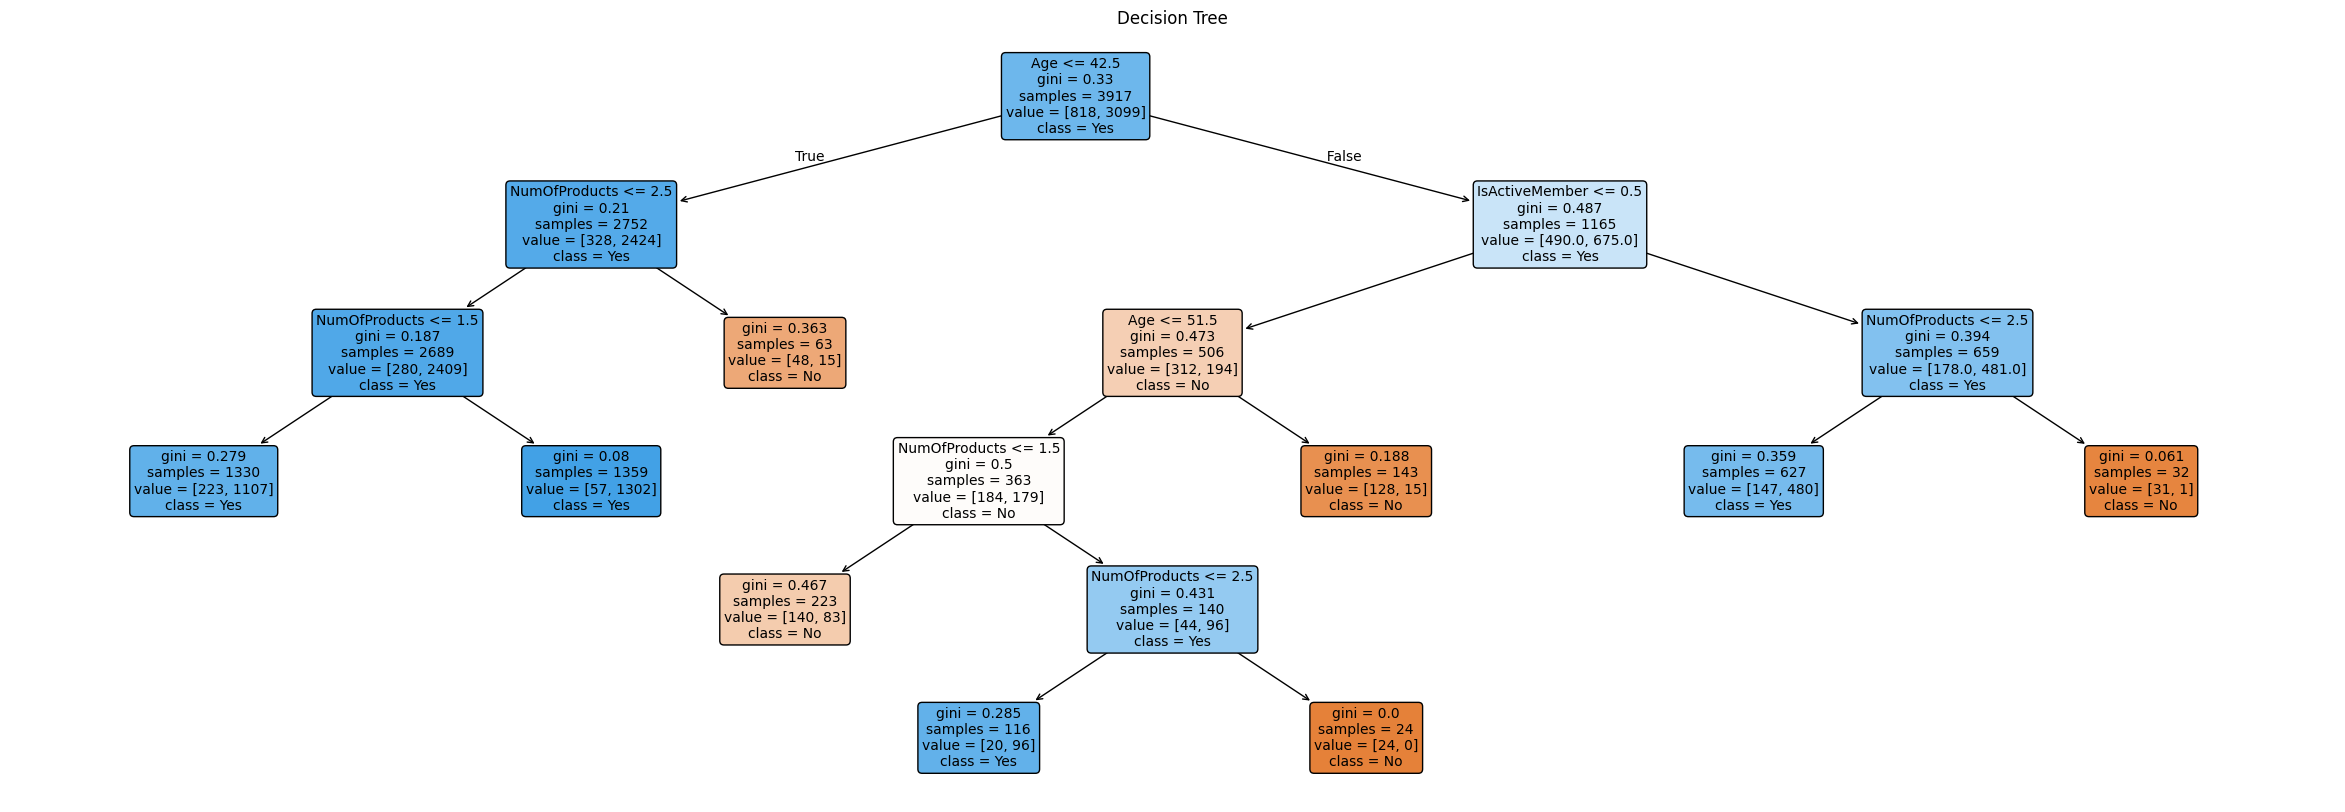

In [71]:
tree = DecisionTreeClassifier(ccp_alpha=best_ccp_alpha,random_state=42)
tree.fit(X_train, y_train)

# Visualizing the decision tree
plt.figure(figsize=[30,10])
plot_tree(tree,
          feature_names=X_train.columns,
          class_names=['No','Yes'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Decision Tree")
plt.show()

In [72]:
# Generating predictions on the test set
y_pred = tree.predict(X_test)

#8. Evaluating the Confusion Matrix

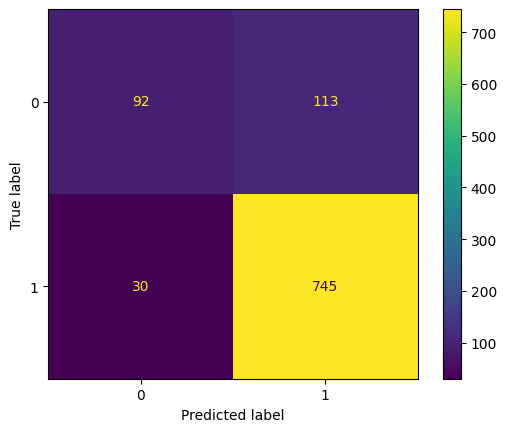

In [73]:
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=tree.classes_)
disp.plot()
plt.show()

### Confusion Matrix Interpretation

The confusion matrix contains four outcomes (positive class: `Stayed = 1`):

- **True Positive (TP = 745):** Customers correctly predicted to stay with the bank.
- **True Negative (TN = 92):** Customers correctly predicted to leave the bank.
- **False Positive (FP = 113):** Customers predicted to stay who actually left.
- **False Negative (FN = 30):** Customers predicted to leave who actually stayed.

#9. Four Classification Metrics

- **Accuracy:** Proportion of all predictions that are correct.
- **Precision:** Proportion of predicted positive cases (`Stayed = 1`) that are truly positive.
- **Recall:** Proportion of actual positive cases (`Stayed = 1`) correctly identified.
- **F1-score:** Harmonic mean of precision and recall, balancing the two metrics.

In [74]:
def compute_basic_eval_measures(cm, model_name=""):

    from pandas import Series

    TP = cm[1,1]
    TN = cm[0,0]
    FP = cm[0,1]
    FN = cm[1,0]

    accuracy = (TP + TN)/cm.sum()
    precision = TP/(TP + FP)
    recall = TP/(TP + FN)
    F1 = 2*precision*recall/(precision + recall)

    return Series(data=[accuracy, precision, recall, F1],
                  index=['accuracy', 'precision', 'recall', 'F1'],
                  name=model_name)

In [75]:
eval1 = compute_basic_eval_measures(cm, 'tree')
eval1

,tree
accuracy,0.854082
precision,0.868298
recall,0.961290
F1,0.912431


### Evaluation Results – Interpretation

**Accuracy:** The model correctly classified 837 out of 979 customers (approximately **85.4%**), whether they stayed or left.

**Precision:** Of all customers predicted to stay, approximately **87%** actually stayed.

**Recall:** Of all customers who actually stayed, approximately **96%** were correctly identified as staying.

**F1-score:** The F1-score is approximately **0.91**, reflecting the combination of high precision and recall for the positive class (`Stayed = 1`).

**Important limitation:** Among 204 customers who actually left, the model correctly identified only 92. Thus, performance for detecting departing customers is weaker than the overall accuracy might suggest.

*Note: These interpretations illustrate one possible way to explain the confusion matrix and metrics in the context of the assignment.*